# Вариант 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Практическая работа №8: Аналитические выводы, сравнение групп и интерпретация визуализаций

**Цель работы:**
Научиться не только строить графики и таблицы, но и интерпретировать результаты EDA: сравнивать группы, выявлять закономерности, избегать типичных ошибок визуального анализа и формулировать осмысленные аналитические выводы по данным.

### Датасеты для работы:
- `data/orders_2024_01.csv`
- `data/orders_2024_02.csv`
- `data/orders_2024_03.csv`

### Подготовка данных

In [2]:
orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]

df_orders = pd.concat([pd.read_csv(f) for f in orders_files], ignore_index=True)
df_orders["order_datetime"] = pd.to_datetime(df_orders["order_datetime"])
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]
df_orders["order_date"] = df_orders["order_datetime"].dt.date
df_orders["order_hour"] = df_orders["order_datetime"].dt.hour
df_orders["weekday"] = df_orders["order_datetime"].dt.day_name()
print(df_orders.head())

   order_id  user_id      order_datetime  ...  order_date  order_hour    weekday
0         1     1044 2024-01-03 18:39:26  ...  2024-01-03          18  Wednesday
1         2     1079 2024-01-03 17:45:43  ...  2024-01-03          17  Wednesday
2         3     1041 2024-01-06 22:46:38  ...  2024-01-06          22   Saturday
3         4     1083 2024-01-08 21:03:51  ...  2024-01-08          21     Monday
4         5     1068 2024-01-03 23:26:53  ...  2024-01-03          23  Wednesday

[5 rows x 11 columns]


### Задание 1. Сравнить sum, mean, median выручки по дням недели

In [3]:
weekday_revenue = df_orders.groupby("weekday")["revenue"].agg(["sum", "mean", "median", "std", "count"])
print(weekday_revenue)

                   sum          mean    median           std  count
weekday                                                            
Friday     52936489.64  25147.976076  19223.13  19193.140759   2105
Monday     54583476.25  25686.341765  19720.49  19538.829416   2125
Saturday   55239314.42  25909.622148  19889.70  19080.405677   2132
Sunday     53393113.93  25340.822938  19449.16  19395.322487   2107
Thursday   57784092.43  25613.516148  19320.44  19270.036247   2256
Tuesday    54367341.28  25644.972302  19860.44  19360.913156   2120
Wednesday  56239823.84  26097.366051  19984.48  19482.699053   2155


### Задание 2. Построить bar chart для суммы и среднего

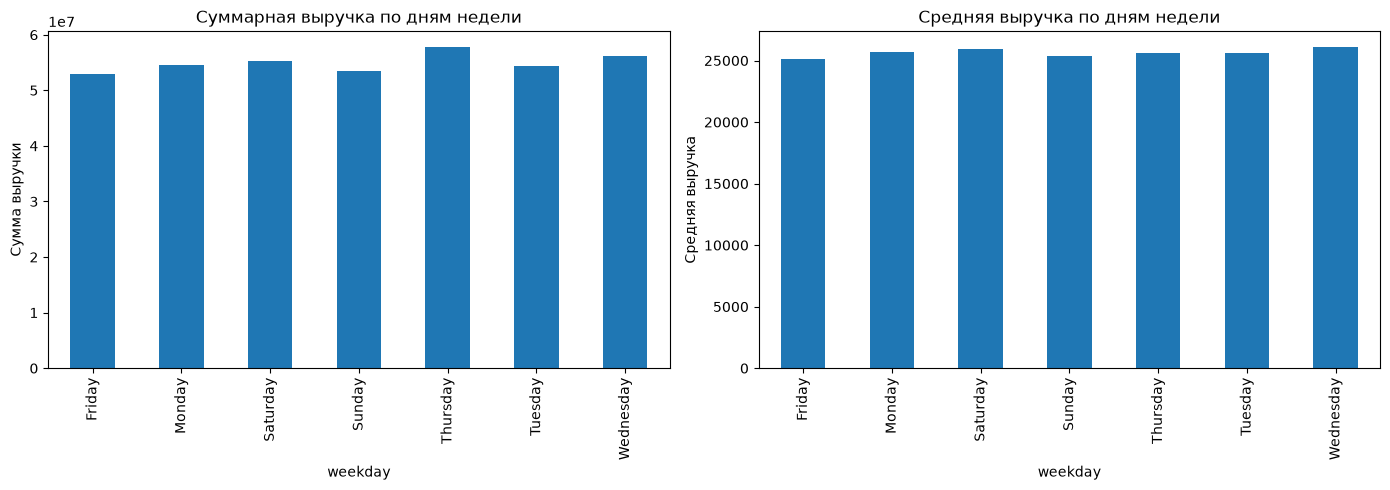

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weekday_revenue["sum"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Суммарная выручка по дням недели")
axes[0].set_ylabel("Сумма выручки")

weekday_revenue["mean"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Средняя выручка по дням недели")
axes[1].set_ylabel("Средняя выручка")

plt.tight_layout()
plt.show()

### Задание 3. Построить boxplot по дням недели

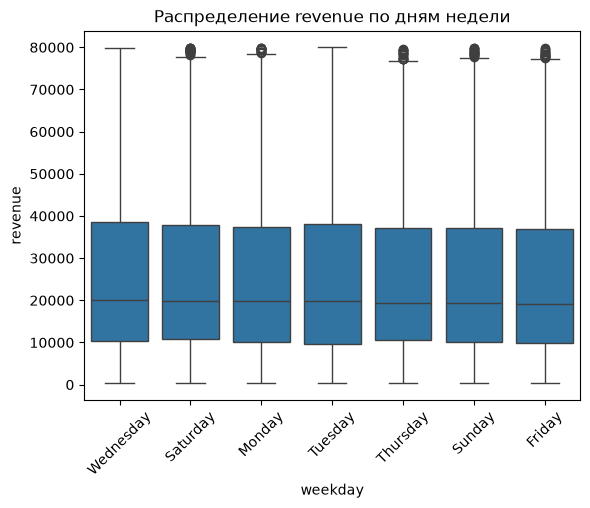

In [5]:
sns.boxplot(data=df_orders, x="weekday", y="revenue")
plt.xticks(rotation=45)
plt.title("Распределение revenue по дням недели")
plt.show()

### Задание 4. Найти день с самой нестабильной выручкой

In [6]:
most_unstable_day = weekday_revenue["std"].idxmax()
print("День с самой нестабильной выручкой (по максимальному std):", most_unstable_day)
print("Стандартное отклонение в этот день:", weekday_revenue.loc[most_unstable_day, "std"])

День с самой нестабильной выручкой (по максимальному std): Monday
Стандартное отклонение в этот день: 19538.829416251345


### Задание 5. Написать 3 аналитических вывода

In [7]:
print("Вывод 1 (Сравнение среднего и медианы):")
print("1. Наблюдение: Во все дни недели средняя выручка (~25.6 тыс. руб.) заметно выше медианной (~19.6 тыс. руб.).")
print("2. Интерпретация: Распределение выручки скошено вправо из-за наличия дорогих заказов и заказов с большим количеством товаров.")
print("3. Следствие: Для оценки типичного чека покупателя следует опираться на медиану, а не на среднее.")

print("\nВывод 2 (Динамика выручки по дням недели):")
print("1. Наблюдение: Наибольшая суммарная выручка наблюдается в четверг (57.78 млн руб.), а наименьшая — в пятницу (52.94 млн руб.).")
print("2. Интерпретация: Активность покупателей концентрируется в середине рабочей недели и снижается перед выходными.")
print("3. Следствие: Маркетинговые акции и промо-кампании эффективнее проводить в среду-четверг.")

print("\nВывод 3 (Нестабильность выручки):")
print("1. Наблюдение: Понедельник (Monday) имеет максимальное стандартное отклонение выручки (std = 19 538.83).")
print("2. Интерпретация: В начале недели разброс между дешевыми и очень дорогими заказами максимален.")
print("3. Следствие: Службе обработки заказов в понедельник требуется учитывать повышенную вариативность объемов заказов.")

Вывод 1 (Сравнение среднего и медианы):
1. Наблюдение: Во все дни недели средняя выручка (~25.6 тыс. руб.) заметно выше медианной (~19.6 тыс. руб.).
2. Интерпретация: Распределение выручки скошено вправо из-за наличия дорогих заказов и заказов с большим количеством товаров.
3. Следствие: Для оценки типичного чека покупателя следует опираться на медиану, а не на среднее.

Вывод 2 (Динамика выручки по дням недели):
1. Наблюдение: Наибольшая суммарная выручка наблюдается в четверг (57.78 млн руб.), а наименьшая — в пятницу (52.94 млн руб.).
2. Интерпретация: Активность покупателей концентрируется в середине рабочей недели и снижается перед выходными.
3. Следствие: Маркетинговые акции и промо-кампании эффективнее проводить в среду-четверг.

Вывод 3 (Нестабильность выручки):
1. Наблюдение: Понедельник (Monday) имеет максимальное стандартное отклонение выручки (std = 19 538.83).
2. Интерпретация: В начале недели разброс между дешевыми и очень дорогими заказами максимален.
3. Следствие: Служб